# Blinkit: Sales & Customer Satisfaction Prediction
Two models on `Blinkit_Preproc_Data.xlsx`:
1. **Sales model** (regression): Linear Regression, Random Forest, XGBoost vs a baseline
2. **Rating model** (classification, since Rating is only 4 or 5): Logistic Regression, Random Forest, XGBoost vs a baseline

Outputs: evaluation tables, saved models (`.pkl`) and CSVs for Power BI.

**Run cells top to bottom.** When asked, upload `Blinkit_Preproc_Data.xlsx`.

In [ ]:
import pandas as pd, numpy as np, joblib, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, f1_score, roc_auc_score, confusion_matrix)
from xgboost import XGBRegressor, XGBClassifier
sns.set_theme(style='whitegrid')
os.makedirs('outputs', exist_ok=True)

## 1. Load data

In [ ]:
FILE = 'Blinkit_Preproc_Data.xlsx'
try:
    from google.colab import files
    if not os.path.exists(FILE):
        up = files.upload()          # choose the Excel file
        FILE = list(up.keys())[0]
except ImportError:
    pass                              # running locally
df = pd.read_excel(FILE)
print(df.shape)
df.head()

Saving Blinkit_Preproc_Data.xlsx to Blinkit_Preproc_Data.xlsx
(1000, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5


## 2. Data checks

In [ ]:
print('Missing values:', df.isna().sum().sum(), '| Duplicates:', df.duplicated().sum())
print(df['Rating'].value_counts())
df.describe().T

Missing values: 0 | Duplicates: 0
Rating
5    685
4    315
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Outlet Establishment Year,1000.0,2016.261000,3.218266,2011.000000,2014.000000,2016.000000,2018.000000,2022.000000
Item Visibility,1000.0,0.068546,0.049443,0.003598,0.029866,0.058633,0.096506,0.291827
Item Weight,1000.0,12.958976,4.353441,4.590000,9.395000,12.857645,16.350000,21.250000
Sales,1000.0,142.592507,60.842529,32.455800,95.492950,146.260200,183.301600,266.888400
Rating,1000.0,4.685000,0.464748,4.000000,4.000000,5.000000,5.000000,5.000000


## 3. Exploratory analysis (also useful for the BI dashboard)

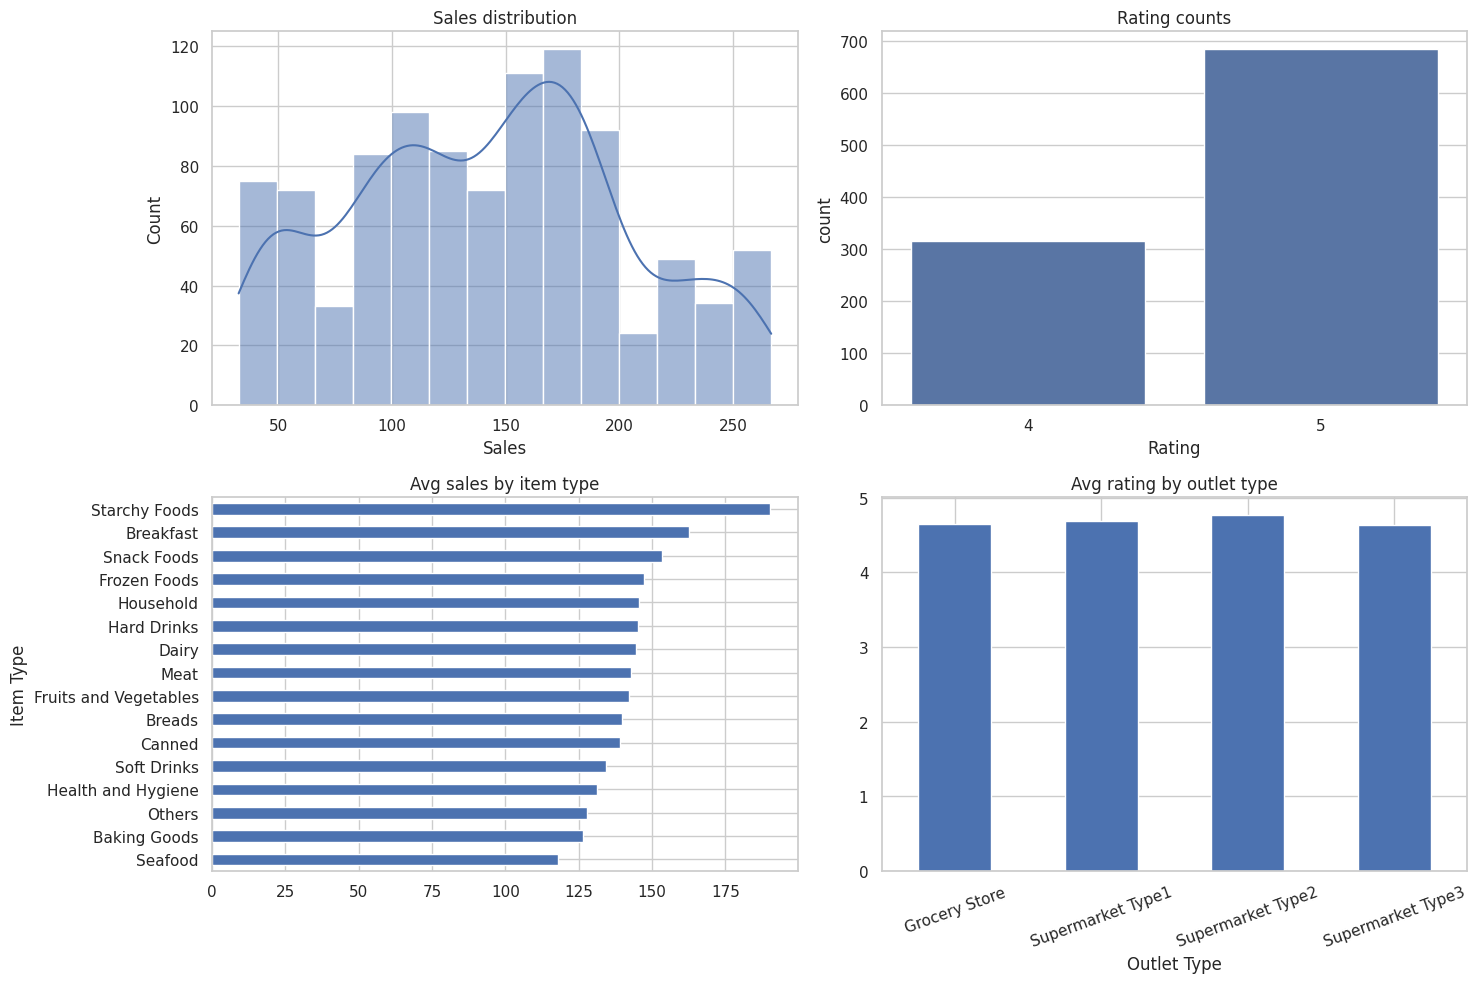

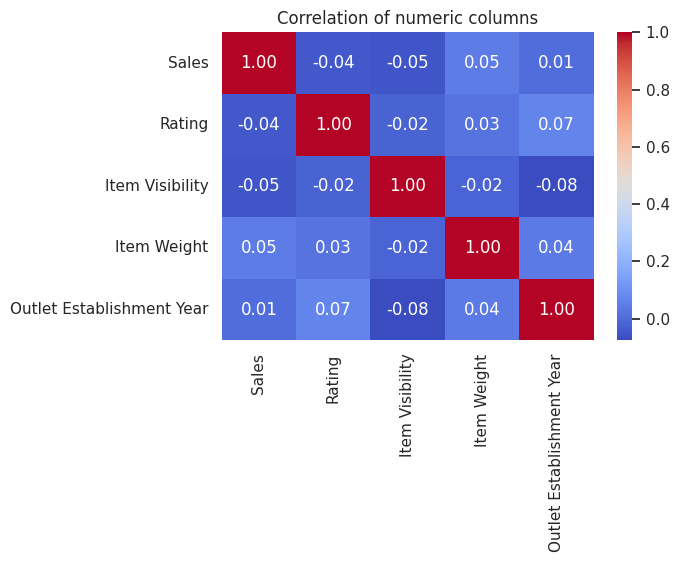

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df['Sales'], kde=True, ax=ax[0,0]).set_title('Sales distribution')
sns.countplot(x='Rating', data=df, ax=ax[0,1]).set_title('Rating counts')
df.groupby('Item Type')['Sales'].mean().sort_values().plot.barh(ax=ax[1,0], title='Avg sales by item type')
df.groupby('Outlet Type')['Rating'].mean().plot.bar(ax=ax[1,1], title='Avg rating by outlet type', rot=20)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4))
sns.heatmap(df[['Sales','Rating','Item Visibility','Item Weight','Outlet Establishment Year']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation of numeric columns'); plt.show()

In [ ]:
# Group-level insights (valid BI findings that don't depend on a predictive model)
for col in ['Item Type', 'Outlet Type', 'Outlet Location Type', 'Outlet Size']:
    display(df.groupby(col).agg(avg_sales=('Sales','mean'), avg_rating=('Rating','mean'),
                                pct_5star=('Rating', lambda s: (s==5).mean()*100),
                                items=('Sales','size')).round(2).sort_values('avg_sales', ascending=False))

,avg_sales,avg_rating,pct_5star,items
Item Type,,,,
Starchy Foods,190.17,4.83,83.33,12
Breakfast,162.49,4.79,78.57,14
Snack Foods,153.22,4.65,65.00,140
Frozen Foods,147.09,4.74,74.00,100
Household,145.42,4.59,58.73,126
Hard Drinks,145.25,4.68,68.18,22
Dairy,144.49,4.67,66.67,75
Meat,142.77,4.82,82.14,56
Fruits and Vegetables,142.15,4.71,71.07,121


,avg_sales,avg_rating,pct_5star,items
Outlet Type,,,,
Supermarket Type2,147.89,4.77,76.84,95
Grocery Store,145.44,4.65,64.89,131
Supermarket Type1,141.61,4.69,68.81,670
Supermarket Type3,140.51,4.63,63.46,104


,avg_sales,avg_rating,pct_5star,items
Outlet Location Type,,,,
Tier 1,145.72,4.63,63.12,301
Tier 2,141.71,4.72,71.90,331
Tier 3,140.83,4.70,69.84,368


,avg_sales,avg_rating,pct_5star,items
Outlet Size,,,,
Small,144.70,4.68,67.78,360
Medium,142.54,4.66,66.07,445
High,138.83,4.75,75.38,195


## 4. Features

In [ ]:
# Item Identifier has 755 unique values and Outlet Identifier duplicates outlet attributes, so both are dropped
cat_cols = ['Item Fat Content','Item Type','Outlet Location Type','Outlet Size','Outlet Type']
num_cols = ['Item Visibility','Item Weight','Outlet Establishment Year']
X = df[cat_cols + num_cols]
y_sales = df['Sales']
y_rating = (df['Rating'] == 5).astype(int)     # 1 = 5 stars, 0 = 4 stars

def prep(scale=False):
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
                              ('num', StandardScaler() if scale else 'passthrough', num_cols)])

X_tr, X_te, ys_tr, ys_te, yr_tr, yr_te = train_test_split(X, y_sales, y_rating, test_size=0.2,
                                                         random_state=42, stratify=y_rating)
print(X_tr.shape, X_te.shape)

(800, 8) (200, 8)


## 5. Model 1: Sales prediction (regression)
Compared against a baseline that always predicts the mean. A model is only useful if it beats the baseline.

In [ ]:
reg_models = {
    'Baseline (mean)': Pipeline([('p', prep()), ('m', DummyRegressor())]),
    'Linear Regression': Pipeline([('p', prep(True)), ('m', LinearRegression())]),
    'Random Forest': Pipeline([('p', prep()), ('m', RandomForestRegressor(300, min_samples_leaf=5, random_state=42))]),
    'XGBoost': Pipeline([('p', prep()), ('m', XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42))]),
}
rows = []
for name, m in reg_models.items():
    m.fit(X_tr, ys_tr); p = m.predict(X_te)
    cv = cross_validate(m, X, y_sales, cv=KFold(5, shuffle=True, random_state=42), scoring='r2')
    rows.append([name, mean_absolute_error(ys_te, p), np.sqrt(mean_squared_error(ys_te, p)),
                 r2_score(ys_te, p), cv['test_score'].mean()])
sales_results = pd.DataFrame(rows, columns=['Model','MAE','RMSE','R2 (test)','R2 (5-fold CV)']).round(3)
sales_results

,Model,MAE,RMSE,R2 (test),R2 (5-fold CV)
0,Baseline (mean),52.653,63.065,-0.042,-0.002
1,Linear Regression,53.397,64.132,-0.078,-0.022
2,Random Forest,50.754,61.938,-0.005,0.029
3,XGBoost,50.212,61.374,0.013,0.031


## 6. Model 2: Customer satisfaction (classify 5-star vs 4-star)

In [ ]:
clf_models = {
    'Baseline (majority)': Pipeline([('p', prep()), ('m', DummyClassifier(strategy='most_frequent'))]),
    'Logistic Regression': Pipeline([('p', prep(True)), ('m', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
    'Random Forest': Pipeline([('p', prep()), ('m', RandomForestClassifier(300, min_samples_leaf=5, class_weight='balanced', random_state=42))]),
    'XGBoost': Pipeline([('p', prep()), ('m', XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42))]),
}
rows = []
for name, m in clf_models.items():
    m.fit(X_tr, yr_tr); p = m.predict(X_te)
    proba = m.predict_proba(X_te)[:, 1]
    cv = cross_validate(m, X, y_rating, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='accuracy')
    rows.append([name, accuracy_score(yr_te, p), f1_score(yr_te, p, zero_division=0),
                 roc_auc_score(yr_te, proba), cv['test_score'].mean()])
rating_results = pd.DataFrame(rows, columns=['Model','Accuracy','F1','ROC-AUC','Accuracy (5-fold CV)']).round(3)
rating_results

,Model,Accuracy,F1,ROC-AUC,Accuracy (5-fold CV)
0,Baseline (majority),0.685,0.813,0.500,0.685
1,Logistic Regression,0.505,0.575,0.512,0.523
2,Random Forest,0.535,0.652,0.479,0.611
3,XGBoost,0.640,0.776,0.486,0.666


## 7. Interpretation
Check the tables above honestly:
- **Sales:** if R² is near or below 0 and MAE is not better than the baseline, the features do not explain sales.
- **Rating:** if accuracy is not above the majority baseline (about 68.5%) and ROC-AUC is near 0.5, the features do not explain ratings.

A weak result is still a valid finding: *outlet and item attributes alone are not enough to predict sales or satisfaction; richer data (price, quantity, customer or time data) is needed.*

Best sales model  : XGBoost
Best rating model : Logistic Regression


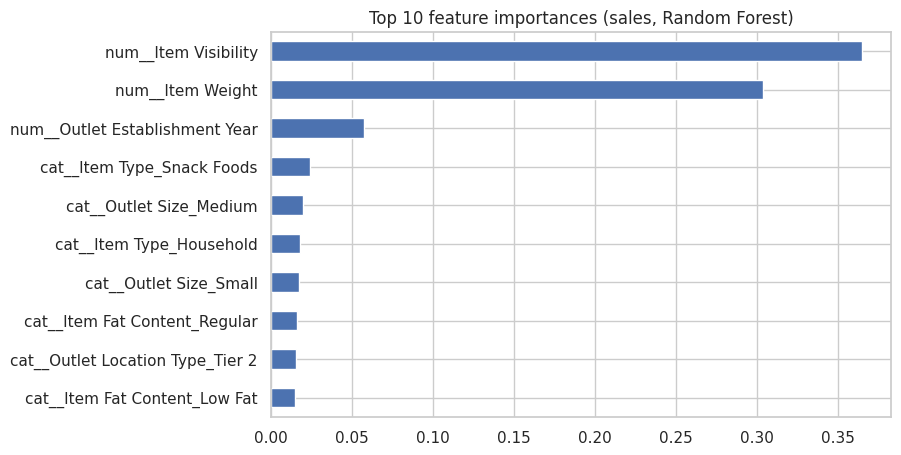

In [ ]:
best_sales = sales_results.iloc[1:].sort_values('R2 (5-fold CV)', ascending=False).iloc[0]['Model']
best_rating = rating_results.iloc[1:].sort_values('ROC-AUC', ascending=False).iloc[0]['Model']
print('Best sales model  :', best_sales)
print('Best rating model :', best_rating)

# Feature importance from Random Forest (what the model leaned on, not proof of causation)
rf = reg_models['Random Forest']
names = rf.named_steps['p'].get_feature_names_out()
imp = pd.Series(rf.named_steps['m'].feature_importances_, index=names).sort_values(ascending=False).head(10)
imp.sort_values().plot.barh(title='Top 10 feature importances (sales, Random Forest)', figsize=(8,5)); plt.show()

## 8. Save models and export predictions for Power BI

In [ ]:
sales_model = reg_models[best_sales].fit(X, y_sales)
rating_model = clf_models[best_rating].fit(X, y_rating)
joblib.dump(sales_model, 'outputs/sales_model.pkl')
joblib.dump(rating_model, 'outputs/rating_model.pkl')

# Out-of-fold predictions: each row is predicted by a model that never saw it (honest, no leakage)
pred = df.copy()
pred['Predicted_Sales'] = cross_val_predict(reg_models[best_sales], X, y_sales,
                                            cv=KFold(5, shuffle=True, random_state=42)).round(2)
pred['Prob_5_Star'] = cross_val_predict(clf_models[best_rating], X, y_rating,
                                        cv=StratifiedKFold(5, shuffle=True, random_state=42),
                                        method='predict_proba')[:, 1].round(3)
pred['Predicted_Rating'] = np.where(pred['Prob_5_Star'] >= 0.5, 5, 4)
pred['Sales_Error'] = (pred['Sales'] - pred['Predicted_Sales']).round(2)

pred.to_csv('outputs/predictions_for_powerbi.csv', index=False)
sales_results.to_csv('outputs/sales_model_results.csv', index=False)
rating_results.to_csv('outputs/rating_model_results.csv', index=False)
pred.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating,Predicted_Sales,Prob_5_Star,Predicted_Rating,Sales_Error
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5,141.179993,0.437,4,4.30
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5,128.559998,0.564,5,-13.21
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5,158.800003,0.548,5,6.22
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5,144.750000,0.562,5,-18.25
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5,121.160004,0.518,5,-66.00


## 9. Predict for a new product/outlet

In [ ]:
new = pd.DataFrame([{
    'Item Fat Content': 'Low Fat', 'Item Type': 'Dairy', 'Outlet Location Type': 'Tier 1',
    'Outlet Size': 'Medium', 'Outlet Type': 'Supermarket Type1',
    'Item Visibility': 0.05, 'Item Weight': 12.0, 'Outlet Establishment Year': 2016}])
print('Predicted sales    :', round(float(sales_model.predict(new)[0]), 2))
print('Prob. of 5-star    :', round(float(rating_model.predict_proba(new)[0, 1]), 3))

Predicted sales    : 147.22
Prob. of 5-star    : 0.396


In [ ]:

try:
    import shutil; from google.colab import files
    shutil.make_archive('blinkit_ml_outputs', 'zip', 'outputs'); files.download('blinkit_ml_outputs.zip')
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MODEL TESTING AND EVALUATION


Sales and Rating Prediction

In [3]:
import joblib, pandas as pd

sales_model  = joblib.load('sales_model.pkl')
rating_model = joblib.load('rating_model.pkl')

new = pd.DataFrame([{
    'Item Fat Content': 'Low Fat',
    'Item Type': 'Dairy',
    'Outlet Location Type': 'Tier 1',
    'Outlet Size': 'Medium',
    'Outlet Type': 'Supermarket Type1',
    'Item Visibility': 0.05,
    'Item Weight': 12.0,
    'Outlet Establishment Year': 2016
}])

print('Predicted sales :', round(float(sales_model.predict(new)[0]), 2))
print('Prob. of 5-star :', round(float(rating_model.predict_proba(new)[0, 1]), 3))

Predicted sales : 147.22
Prob. of 5-star : 0.396


In [7]:
import joblib, pandas as pd

sales_model  = joblib.load('sales_model.pkl')
rating_model = joblib.load('rating_model.pkl')

test = pd.DataFrame([
    {'Item Fat Content': 'Regular', 'Item Type': 'Snack Foods', 'Outlet Location Type': 'Tier 3',
     'Outlet Size': 'Small', 'Outlet Type': 'Supermarket Type2',
     'Item Visibility': 0.08, 'Item Weight': 9.5, 'Outlet Establishment Year': 2014},
    {'Item Fat Content': 'Low Fat', 'Item Type': 'Fruits and Vegetables', 'Outlet Location Type': 'Tier 2',
     'Outlet Size': 'High', 'Outlet Type': 'Supermarket Type3',
     'Item Visibility': 0.02, 'Item Weight': 15.0, 'Outlet Establishment Year': 2018},
    {'Item Fat Content': 'Regular', 'Item Type': 'Soft Drinks', 'Outlet Location Type': 'Tier 1',
     'Outlet Size': 'Small', 'Outlet Type': 'Grocery Store',
     'Item Visibility': 0.12, 'Item Weight': 18.5, 'Outlet Establishment Year': 2011},
    {'Item Fat Content': 'Low Fat', 'Item Type': 'Health and Hygiene', 'Outlet Location Type': 'Tier 3',
     'Outlet Size': 'Medium', 'Outlet Type': 'Supermarket Type1',
     'Item Visibility': 0.20, 'Item Weight': 6.0, 'Outlet Establishment Year': 2022},
    {'Item Fat Content': 'Regular', 'Item Type': 'Frozen Foods', 'Outlet Location Type': 'Tier 2',
     'Outlet Size': 'Medium', 'Outlet Type': 'Supermarket Type2',
     'Item Visibility': 0.15, 'Item Weight': 20.0, 'Outlet Establishment Year': 2015},
])

test['Predicted_Sales'] = sales_model.predict(test).round(2)
test['Prob_5_Star'] = rating_model.predict_proba(test)[:, 1].round(3)
test['Predicted_Rating'] = (test['Prob_5_Star'] >= 0.5).map({True: 5, False: 4})
test

,Item Fat Content,Item Type,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Outlet Establishment Year,Predicted_Sales,Prob_5_Star,Predicted_Rating
0,Regular,Snack Foods,Tier 3,Small,Supermarket Type2,0.08,9.5,2014,171.949997,0.575,5
1,Low Fat,Fruits and Vegetables,Tier 2,High,Supermarket Type3,0.02,15.0,2018,123.720001,0.647,5
2,Regular,Soft Drinks,Tier 1,Small,Grocery Store,0.12,18.5,2011,139.830002,0.485,4
3,Low Fat,Health and Hygiene,Tier 3,Medium,Supermarket Type1,0.20,6.0,2022,98.269997,0.444,4
4,Regular,Frozen Foods,Tier 2,Medium,Supermarket Type2,0.15,20.0,2015,155.309998,0.722,5


In [8]:
import joblib, pandas as pd

sales_model  = joblib.load('sales_model.pkl')
rating_model = joblib.load('rating_model.pkl')

test = pd.DataFrame([
    {'Item Fat Content': 'Low Fat', 'Item Type': 'Dairy', 'Outlet Location Type': 'Tier 2',
     'Outlet Size': 'High', 'Outlet Type': 'Supermarket Type3',
     'Item Visibility': 0.03, 'Item Weight': 11.0, 'Outlet Establishment Year': 2018},
    {'Item Fat Content': 'Regular', 'Item Type': 'Meat', 'Outlet Location Type': 'Tier 1',
     'Outlet Size': 'Medium', 'Outlet Type': 'Supermarket Type1',
     'Item Visibility': 0.10, 'Item Weight': 13.5, 'Outlet Establishment Year': 2012},
    {'Item Fat Content': 'Low Fat', 'Item Type': 'Breads', 'Outlet Location Type': 'Tier 3',
     'Outlet Size': 'Small', 'Outlet Type': 'Grocery Store',
     'Item Visibility': 0.25, 'Item Weight': 7.5, 'Outlet Establishment Year': 2017},
    {'Item Fat Content': 'Regular', 'Item Type': 'Household', 'Outlet Location Type': 'Tier 2',
     'Outlet Size': 'Medium', 'Outlet Type': 'Supermarket Type2',
     'Item Visibility': 0.06, 'Item Weight': 16.0, 'Outlet Establishment Year': 2016},
    {'Item Fat Content': 'Low Fat', 'Item Type': 'Breakfast', 'Outlet Location Type': 'Tier 1',
     'Outlet Size': 'High', 'Outlet Type': 'Supermarket Type3',
     'Item Visibility': 0.04, 'Item Weight': 8.5, 'Outlet Establishment Year': 2022},
    {'Item Fat Content': 'Regular', 'Item Type': 'Hard Drinks', 'Outlet Location Type': 'Tier 3',
     'Outlet Size': 'Medium', 'Outlet Type': 'Supermarket Type1',
     'Item Visibility': 0.18, 'Item Weight': 19.0, 'Outlet Establishment Year': 2015},
    {'Item Fat Content': 'Low Fat', 'Item Type': 'Seafood', 'Outlet Location Type': 'Tier 2',
     'Outlet Size': 'Small', 'Outlet Type': 'Supermarket Type2',
     'Item Visibility': 0.09, 'Item Weight': 10.0, 'Outlet Establishment Year': 2014},
    {'Item Fat Content': 'Regular', 'Item Type': 'Baking Goods', 'Outlet Location Type': 'Tier 1',
     'Outlet Size': 'Small', 'Outlet Type': 'Grocery Store',
     'Item Visibility': 0.28, 'Item Weight': 14.0, 'Outlet Establishment Year': 2011},
])

test['Predicted_Sales'] = sales_model.predict(test).round(2)
test['Prob_5_Star'] = rating_model.predict_proba(test)[:, 1].round(3)
test['Predicted_Rating'] = (test['Prob_5_Star'] >= 0.5).map({True: 5, False: 4})
test

,Item Fat Content,Item Type,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Outlet Establishment Year,Predicted_Sales,Prob_5_Star,Predicted_Rating
0,Low Fat,Dairy,Tier 2,High,Supermarket Type3,0.03,11.0,2018,160.779999,0.589,5
1,Regular,Meat,Tier 1,Medium,Supermarket Type1,0.10,13.5,2012,139.000000,0.597,5
2,Low Fat,Breads,Tier 3,Small,Grocery Store,0.25,7.5,2017,132.940002,0.342,4
3,Regular,Household,Tier 2,Medium,Supermarket Type2,0.06,16.0,2016,149.490005,0.587,5
4,Low Fat,Breakfast,Tier 1,High,Supermarket Type3,0.04,8.5,2022,150.649994,0.662,5
5,Regular,Hard Drinks,Tier 3,Medium,Supermarket Type1,0.18,19.0,2015,141.270004,0.483,4
6,Low Fat,Seafood,Tier 2,Small,Supermarket Type2,0.09,10.0,2014,125.129997,0.613,5
7,Regular,Baking Goods,Tier 1,Small,Grocery Store,0.28,14.0,2011,160.520004,0.467,4


In [9]:
import pandas as pd

test = pd.DataFrame([
    {'Item Fat Content': 'Low Fat', 'Item Type': 'Dairy', 'Outlet Location Type': 'Tier 1',
     'Outlet Size': 'Medium', 'Outlet Type': 'Supermarket Type1',
     'Item Visibility': 0.05, 'Item Weight': 12.0, 'Outlet Establishment Year': 2016},
    {'Item Fat Content': 'Regular', 'Item Type': 'Snack Foods', 'Outlet Location Type': 'Tier 3',
     'Outlet Size': 'Small', 'Outlet Type': 'Supermarket Type2',
     'Item Visibility': 0.08, 'Item Weight': 9.5, 'Outlet Establishment Year': 2014},
])

test['Predicted_Sales'] = sales_model.predict(test).round(2)
test['Prob_5_Star'] = rating_model.predict_proba(test)[:, 1].round(3)
test['Predicted_Rating'] = (test['Prob_5_Star'] >= 0.5).map({True: 5, False: 4})
test

,Item Fat Content,Item Type,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Outlet Establishment Year,Predicted_Sales,Prob_5_Star,Predicted_Rating
0,Low Fat,Dairy,Tier 1,Medium,Supermarket Type1,0.05,12.0,2016,147.220001,0.396,4
1,Regular,Snack Foods,Tier 3,Small,Supermarket Type2,0.08,9.5,2014,171.949997,0.575,5
